# pxGPT — schema-constrained phenotype extraction: evaluation-stage reproduction (seedling dataset)

**Paper:** Po-Xing Zheng, Jheng-Yan Ou, Yu-Lin Wu, Ruei-Shiuan Wang, Ting-Li Wu, Te-Chang Hsu, Yao-Ching Lin (2026). *pxGPT: a schema-constrained multimodal large language model framework for plant phenotyping.* Bioinformatics 42(10):btag781. [DOI](https://doi.org/10.1093/bioinformatics/btag781) · [PMC13719227](https://pmc.ncbi.nlm.nih.gov/articles/PMC13719227/)

**Code (authors, MIT):** [YaoChengLab/pxgpt](https://github.com/YaoChengLab/pxgpt) @ commit `9cd5d2e2` = **v0.4.0** — per the repository CHANGELOG, the version used for the revision of this Bioinformatics application note.
**Data (authors, CC BY 4.0):** Zenodo [10.5281/zenodo.22907554](https://doi.org/10.5281/zenodo.22907554) v2.0.0 — photos, curated schemas, Step-1 narratives, **deposited Step-3 model outputs**, human scores, and reference labels.

**Scope (partial demonstration).** pxGPT's Step 3 sends plant photos to a commercial vision LLM (Claude Sonnet 5) behind a paid API key, so live extraction cannot run here without credentials. This notebook instead reproduces the paper's **evaluation stage** for the *seedling* dataset using the authors' own deposited Step-3 outputs: (1) preview a real sample (`seedling/s0001`, 7 views) with its narrative and deposited extraction record, and verify the deposit README's worked example; (2) run the authors' own `pxgpt json-to-table` CLI on the deposited record; (3) compute per-trait accuracy, balanced accuracy, macro-F1, Cohen's kappa, and raw agreement (pxGPT–human, human–human, bootstrap gap CI) exactly as described in the paper's Results; (4) compare with the published seedling mean accuracy **0.619**. An optional final cell runs live `pxgpt schema` extraction if *you* supply your own Anthropic API key.

**制限事項（日本語）:** このノートブックは論文の評価ステージを再現します。Step 3 の実際の抽出には有料 LLM API キーが必要なため、ここでは著者自身が Zenodo に公開した Step 3 出力（claude-sonnet-5）を用いて、論文記載の精度指標（trait 別 accuracy・balanced accuracy・macro-F1・Cohen's kappa・raw agreement）を再計算し、公表値 0.619 と比較します。単一データセット（seedling）の部分再現であり、論文の全結果の検証ではありません。

**AI-assisted metrics notice:** the authors' repository ships no scoring script; the metric cells below are an AI implementation that follows the paper's Results text (accuracy per qualitative trait averaged across traits; balanced accuracy, macro-F1, Cohen's kappa; raw agreement on combinations with ≥2 annotations, equal weight per combination; 2000-sample bootstrap for the agreement-gap CI). The `pxgpt` CLI steps are the authors' own pinned code.

**Execution status:** see the final interpretation section; saved outputs were produced by a fresh Google Colab CPU runtime.

## Runtime selection and how to run

**Select the CPU runtime** (Runtime → Change runtime type → CPU). No GPU and no deep-learning framework are used anywhere in this notebook — every operation is tabular joining, metric computation, JPEG display, and one author-CLI flattening pass.

Run **Runtime → Run all**. Measured on a fresh Colab CPU runtime (see the saved outputs): pip install ≈ 1 min, docs archive ≈ 10 s, seedling photo archive **1.88 GB** ≈ 3–10 min depending on Zenodo throughput, metrics ≈ 1 min. The 1.88 GB archive download is unavoidable: the seedling photos, schemas, and the deposited Step-3 values used for scoring live inside one `tar.gz`, and scoring all resolved seedling sample–trait pairs requires the full deposited table.

**実行方法（日本語）:** ランタイムは **CPU** を選択してください（GPU 不要）。「ランタイム → すべてのセルを実行」で実行します。写真アーカイブ 1.88 GB のダウンロードが含まれるため、全体で 10〜20 分程度かかります。

**What is NOT reproduced:** live LLM extraction (paid API key), the mature_v1/mature_v2 datasets, quantitative-trait metrics (Table S4), supplementary Tables S1–S8 values, and the paper's full cross-model/ablation analyses.

## 1. Environment check

We print the actual runtime versions (nothing is assumed). The executed path needs only `pandas`, `numpy`, `matplotlib`, `Pillow`, `requests`, and `scikit-learn` — all preinstalled on current Colab images.

**環境確認（日本語）:** 実行環境のバージョンを表示します。必要なライブラリは Colab に標準搭載されています。

In [ ]:
import sys
print("Python:", sys.version.split()[0])
import numpy as np, pandas as pd, matplotlib, requests, PIL
print("pandas:", pd.__version__, "| numpy:", np.__version__,
      "| matplotlib:", matplotlib.__version__, "| requests:", requests.__version__, "| Pillow:", PIL.__version__)
try:
    import sklearn
    print("scikit-learn:", sklearn.__version__)
except ImportError:
    print("scikit-learn: MISSING")

Python: 3.13.18


pandas: 2.2.3 | numpy: 2.4.6 | matplotlib: 3.10.0 | requests: 2.32.4 | Pillow: 11.3.0


scikit-learn: 1.6.1


## 2. Install the authors' pxGPT CLI (pinned revision)

We install exactly the paper-matched release **v0.4.0** by pinning commit `9cd5d2e20c810ac73fe48a16e2728f43b2d0dfa6` (verified via the repository CHANGELOG: v0.4.0 is the version used for the paper revision). This provides `pxgpt json-to-table` (used in §5, no API key needed) and `pxgpt schema` (only used by the optional live-extraction cell).

**著者の CLI を固定リビジョンでインストール（日本語）:** 論文リビジョンと一致する v0.4.0 のコミットを固定してインストールします。

In [ ]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/YaoChengLab/pxgpt.git@9cd5d2e20c810ac73fe48a16e2728f43b2d0dfa6"],
                   timeout=600)
assert r.returncode == 0, "pxgpt installation failed"
import importlib.metadata as im
print("pxgpt version installed:", im.version("pxgpt"))
h = subprocess.run(["pxgpt", "--help"], capture_output=True, text=True, timeout=120)
print("\n".join(h.stdout.splitlines()[:14]))

pxgpt version installed: 0.4.0


usage: pxgpt [-h] [--version] [--verbose]
             {analyze,schema,describe-batch,phenotype-batch,describe-batch-openai,phenotype-batch-openai,fetch-results,cleanup-files,extract-report,normalize-schema,shard-schema,json-to-table} ...

Plant analysis tool — multi-provider LLM with Files + Batch API support

options:
  -h, --help            show this help message and exit
  --version             show program's version number and exit
  --verbose             Enable verbose output

Commands:
  Available commands

  {analyze,schema,describe-batch,phenotype-batch,describe-batch-openai,phenotype-batch-openai,fetch-results,cleanup-files,extract-report,normalize-schema,shard-schema,json-to-table}


## 3. Download the small docs archive from Zenodo (checksum-verified)

Everything here comes from the authors' Zenodo record **10.5281/zenodo.22907554 (v2.0.0, CC BY 4.0)**. We query the public record API, take each file's official content link and MD5 checksum from the API response itself (no hardcoded hashes), stream the download while computing MD5, and verify before extraction. This 1.8 MB archive holds the join tables: `records.csv`, `human_scores.csv`, `reference_labels.csv`, `trait_dictionary.csv`.

**Zenodo からドキュメントアーカイブを取得（日本語）:** 公開 API からファイル配布 URL と MD5 を取得し、ダウンロード中に MD5 を検証してから展開します（約 1.8 MB）。

In [ ]:
import hashlib, json, tarfile
from pathlib import Path
import requests

ZENODO_RECORD = "https://zenodo.org/api/records/22907554"  # dataset v2.0.0, CC BY 4.0
BASE = Path("/content")
RELEASE = BASE / "pxgpt_brassica_release"

rec = requests.get(ZENODO_RECORD, timeout=60)
rec.raise_for_status()
rec = rec.json()
zfiles = {f["key"]: f for f in rec["files"]}
print("record:", rec["metadata"]["title"], "| version:", rec["metadata"]["version"])

def zenodo_fetch(key: str, dest: Path) -> Path:
    """Stream a Zenodo file, verify its API-provided MD5, return the local path."""
    meta = zfiles[key]
    expect = meta["checksum"].split(":", 1)[1]  # API format: "md5:<hex>"
    h, n = hashlib.md5(), 0
    with requests.get(meta["links"]["self"], stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as out:
            for chunk in r.iter_content(chunk_size=1 << 22):  # 4 MiB
                out.write(chunk); h.update(chunk); n += len(chunk)
    assert h.hexdigest() == expect, f"MD5 mismatch for {key}: {h.hexdigest()} != {expect}"
    print(f"{key}: {n/1e6:.1f} MB, MD5 OK")
    return dest

def safe_extract(tf, member, dest):
    try:
        tf.extract(member, dest, filter="data")
    except TypeError:  # older Python tarfile without extraction filters
        tf.extract(member, dest)

docs_tgz = zenodo_fetch("pxgpt_release_docs_and_human_annotations.tar.gz", BASE / "docs.tar.gz")
with tarfile.open(docs_tgz, "r:gz") as tf:
    for m in tf:
        if m.isfile():
            safe_extract(tf, m, BASE)
print("release dir exists:", RELEASE.exists())
print(sorted(p.name for p in (RELEASE / "tables").iterdir()))

record: Multi-stage Phenotype Dataset of Brassica Cultivars with LLM-assisted Annotations | version: v2.0.0


pxgpt_release_docs_and_human_annotations.tar.gz: 1.8 MB, MD5 OK
release dir exists: True
['annotators.csv', 'datasets.csv', 'group_assignments.csv', 'human_scores.csv', 'images.csv', 'model_runs.csv', 'records.csv', 'reference_labels.csv', 'trait_dictionary.csv', 'trait_translations_en_zh.csv']


## 4. Download the seedling photo archive and extract only the needed members

The seedling dataset archive (1.88 GB) contains all 284 records' photos plus schemas, narratives, and model results. We verify its MD5 while streaming, then extract **only** what this notebook uses: the 7 photos of record `s0001`, its Step-1 narrative, its deposited Step-3 JSON (claude-sonnet-5 and gemma4), the seedling schema directory, and the standardized long-format Step-3 values table used for scoring all 284 records. The full bytes must still be downloaded (single compressed archive) — that cost is disclosed in the runtime cell.

**シードリング画像アーカイブを取得（日本語）:** 1.88 GB のアーカイブを MD5 検証付きでダウンロードし、このノートブックで使うメンバー（s0001 の写真 7 枚・Step 1 叙述・Step 3 JSON・スキーマ・採点用の長形式テーブル）だけを展開します。

In [ ]:
WANT = (
    "pxgpt_brassica_release/datasets/seedling/images/s0001/",
    "pxgpt_brassica_release/datasets/seedling/step1_narratives/by_record/s0001.txt",
    "pxgpt_brassica_release/datasets/seedling/step3_json/claude-sonnet-5/s0001.json",
    "pxgpt_brassica_release/datasets/seedling/step3_json/gemma4/s0001.json",
    "pxgpt_brassica_release/datasets/seedling/schema/",
    "pxgpt_brassica_release/datasets/seedling/model_tables/standardized/seedling_step3_values_long.csv",
)
seed_tgz = zenodo_fetch("pxgpt_release_seedling_dataset.tar.gz", BASE / "seedling.tar.gz")
extracted = []
with tarfile.open(seed_tgz, "r:gz") as tf:
    for m in tf:
        if m.isfile() and m.name.replace("./", "").startswith(WANT):
            safe_extract(tf, m, BASE)
            extracted.append(m.name)
print(f"{len(extracted)} members extracted:")
for name in extracted:
    print("  ", name)
seed_tgz.unlink()  # free the 1.9 GB archive; extracted files stay under /content

pxgpt_release_seedling_dataset.tar.gz: 1883.5 MB, MD5 OK


28 members extracted:
   pxgpt_brassica_release/datasets/seedling/images/s0001/s0001_20250101-001.jpg
   pxgpt_brassica_release/datasets/seedling/images/s0001/s0001_20250101-002.jpg
   pxgpt_brassica_release/datasets/seedling/images/s0001/s0001_20250101-003.jpg
   pxgpt_brassica_release/datasets/seedling/images/s0001/s0001_20250101-004.jpg
   pxgpt_brassica_release/datasets/seedling/images/s0001/s0001_20250101-005.jpg
   pxgpt_brassica_release/datasets/seedling/images/s0001/s0001_20250101-006.jpg
   pxgpt_brassica_release/datasets/seedling/images/s0001/s0001_20250101-007.jpg
   pxgpt_brassica_release/datasets/seedling/model_tables/standardized/seedling_step3_values_long.csv
   pxgpt_brassica_release/datasets/seedling/schema/master_schema.json
   pxgpt_brassica_release/datasets/seedling/schema/shard_master_schema/shard_01.prompt.md
   pxgpt_brassica_release/datasets/seedling/schema/shard_master_schema/shard_01.schema.json
   pxgpt_brassica_release/datasets/seedling/schema/shard_master_s

## 5. Inspect the join tables

The deposit README guarantees that every record-level table carries `dataset_id` and `record_id`, and that human scores and model values join on `dataset_id + record_id + trait`. We print each table's actual shape and columns, then show the `seedling/s0001` rows.

**結合テーブルの確認（日本語）:** 各テーブルの実際の列とサイズを表示し、`seedling/s0001` の行を確認します。

In [ ]:
TAB = RELEASE / "tables"
records = pd.read_csv(TAB / "records.csv")
human = pd.read_csv(TAB / "human_scores.csv")
ref = pd.read_csv(TAB / "reference_labels.csv")
tdict = pd.read_csv(TAB / "trait_dictionary.csv")
for name, df in [("records", records), ("human_scores", human),
                 ("reference_labels", ref), ("trait_dictionary", tdict)]:
    print(f"--- {name}: {df.shape}")
    print("   columns:", list(df.columns))

seed_records = records[records.dataset_id == "seedling"]
print("\nseedling records:", len(seed_records))
print("s0001 row:")
print(records[(records.dataset_id == "seedling") & (records.record_id == "s0001")].T)
print("\nreference_status values (seedling):")
print(ref[ref.dataset_id == "seedling"].reference_status.value_counts())

--- records: (703, 14)
   columns: ['dataset_id', 'record_id', 'cultivar_id', 'n_images', 'image_folder', 'step1_narrative', 'step1_narrative_additional_claude_sonnet_4_6', 'step3_json_claude_sonnet_5', 'step3_json_gemma4', 'step3_json_gpt_5_6_luna', 'record_note', 'human_group', 'n_human_annotators', 'human_annotator_codes']
--- human_scores: (78973, 9)
   columns: ['dataset_id', 'record_id', 'cultivar_id', 'annotator_code', 'group_id', 'shard_id', 'trait', 'scale_type', 'value']
--- reference_labels: (27566, 13)
   columns: ['dataset_id', 'record_id', 'cultivar_id', 'trait', 'scale_type', 'n_scores', 'n_not_assessable', 'reference_value', 'reference_status', 'top_value_count', 'agreement_fraction', 'unanimous', 'scores_by_annotator']
--- trait_dictionary: (141, 14)
   columns: ['dataset_id', 'schema_version', 'shard_id', 'trait_group', 'trait', 'scale_type', 'unit', 'allowed_values', 'ordinal_levels', 'not_assessable_allowed', 'source_table_column', 'codebook_file', 'description_en',

## 6. Input preview: the 7 views of sample `seedling/s0001`

These are the real input photos that pxGPT's Step 3 would send to the LLM (all views of one sample together, per the paper's Implementation section). This grid is an actual deposited input image — not a model output.

**入力プレビュー（日本語）:** `seedling/s0001` の 7 枚の実写写真（Zenodo v2.0.0 より）。これが Step 3 の抽出で LLM に渡される実入力です。

7 photos found for seedling/s0001:
   s0001_20250101-001.jpg (1568, 1043)
   s0001_20250101-002.jpg (1568, 1043)
   s0001_20250101-003.jpg (1568, 1043)
   s0001_20250101-004.jpg (1568, 1043)
   s0001_20250101-005.jpg (1568, 1043)
   s0001_20250101-006.jpg (1568, 1043)
   s0001_20250101-007.jpg (1568, 1043)


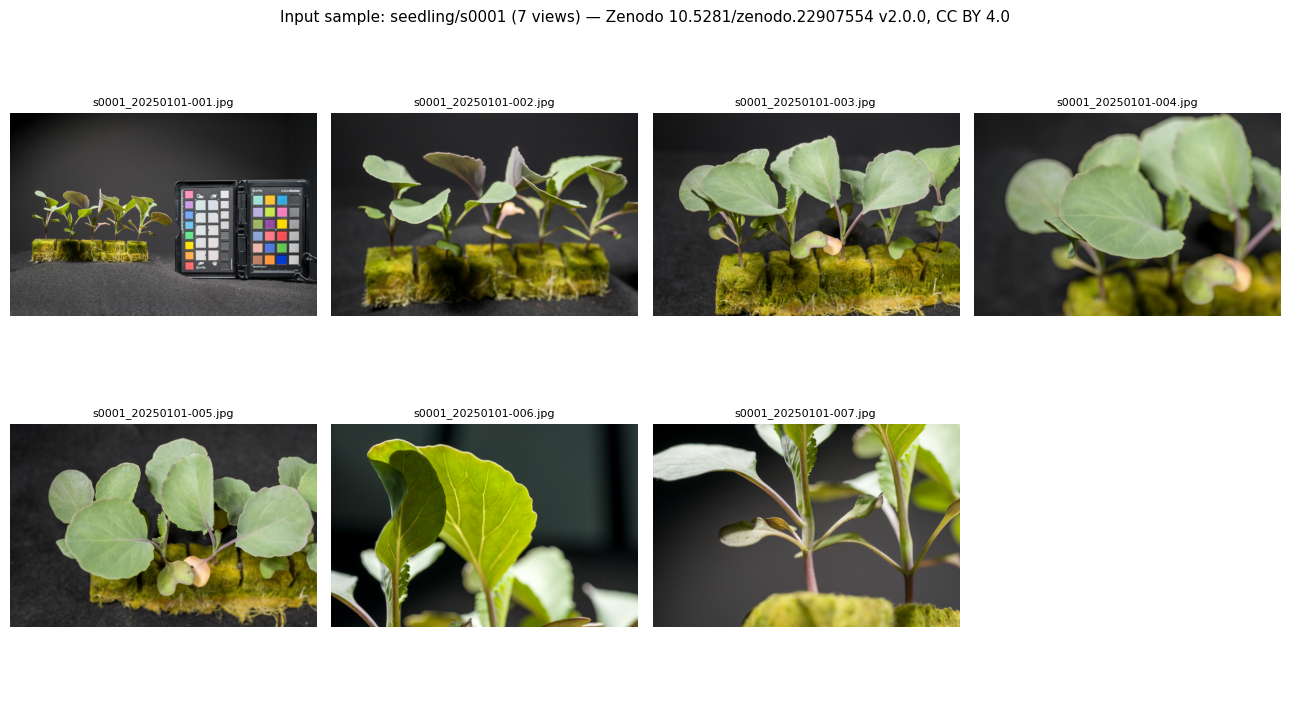

In [ ]:
import glob
import matplotlib.pyplot as plt
from PIL import Image

photos = sorted(glob.glob(str(RELEASE / "datasets/seedling/images/s0001/*.jpg")))
print(f"{len(photos)} photos found for seedling/s0001:")
for p in photos:
    print("  ", Path(p).name, Image.open(p).size)

ncols = 4
nrows = int(np.ceil(len(photos) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.6 * nrows))
for ax, p in zip(np.ravel(axes), photos):
    ax.imshow(Image.open(p))
    ax.set_title(Path(p).name, fontsize=8)
    ax.axis("off")
for ax in np.ravel(axes)[len(photos):]:
    ax.axis("off")
fig.suptitle("Input sample: seedling/s0001 (7 views) — Zenodo 10.5281/zenodo.22907554 v2.0.0, CC BY 4.0",
             fontsize=11)
fig.tight_layout()
fig.savefig("s0001_photos.png", dpi=110, bbox_inches="tight")
plt.show()

## 7. Worked example from the deposit README: `leaf_posture` of `s0001`

The deposit README documents an expected relationship for this sample–trait: the deposited model value is `2`, human annotators B1–B4 scored `2,1,2,1`, and the reference label is `2` (`ordinal_median_tiebreak`: median 1.5 rounds to the even level 2). We verify this end-to-end from the actual deposited bytes: the Step-1 narrative, the claude-sonnet-5 Step-3 JSON, the human scores, and the reference label.

**作業例の検証（日本語）:** デポジット README の作業例（`leaf_posture`: モデル値 2、ヒューマン 2,1,2,1、参照ラベル 2）を実際のファイルから検証します。

In [ ]:
import json

narr_path = RELEASE / "datasets/seedling/step1_narratives/by_record/s0001.txt"
print("--- Step 1 narrative for s0001 (first 700 chars) ---")
print(narr_path.read_text()[:700])

def find_trait(node, key, path=""):
    """Return (json_path, value) pairs for a trait key anywhere in the record JSON."""
    hits = []
    if isinstance(node, dict):
        for k, v in node.items():
            if k == key:
                hits.append((path + "/" + k, v))
            hits += find_trait(v, key, path + "/" + k)
    return hits

step3 = json.load(open(RELEASE / "datasets/seedling/step3_json/claude-sonnet-5/s0001.json"))
print("\ntop-level keys of deposited Step-3 JSON:", list(step3.keys()))
for path, val in find_trait(step3, "leaf_posture"):
    print("\nclaude-sonnet-5 JSON path:", path)
    print("  value:", val.get("value"), "| rationale:", str(val.get("rationale"))[:200])

hsub = human[(human.dataset_id == "seedling") & (human.record_id == "s0001")
             & (human.trait == "leaf_posture")]
print("\nhuman scores for seedling/s0001/leaf_posture:")
print(hsub)
rsub = ref[(ref.dataset_id == "seedling") & (ref.record_id == "s0001")
           & (ref.trait == "leaf_posture")]
print("\nreference label row:")
print(rsub.T)

--- Step 1 narrative for s0001 (first 700 chars) ---
### s0001

# Morphological Analysis Report: Brassica Seedling Cultivar

## 1. Developmental Stage Assessment

All specimens represent **early post-germination seedlings** at the true-leaf initiation stage. Each of the five individuals (grown in discrete 2.5 cm rockwool propagation cubes) displays:
- Persistent, still-intact **cotyledons** (visible in images 2, 3, 5) — reniform/kidney-shaped, folded along the midrib
- **1–3 true leaves** emerging above the cotyledons
- **No inflorescence meristem, floral buds, or bolting stem** are present in any overhead or close-up view — this rules out cauliflower/broccoli curd formation at this stage and confirms a purely vegetative phase
- No flower colo

top-level keys of deposited Step-3 JSON: ['whole_plant_architecture', 'root_system', 'hypocotyl_stem', 'cotyledon', 'leaf_blade', 'leaf_margin', 'leaf_apex_base', 'leaf_surface', 'venation', 'petiole', 'phenology', 'plant_health']

claude-sonnet

## 8. Run the authors' own `pxgpt json-to-table` on the deposited record

The authors' CLI flattens a per-plant Step-3 JSON into a typed table (ordinal traits reconstructed from level codes to labels). We run it, pinned v0.4.0, on the deposited `s0001` record with the deposited seedling master schema — this exercises the authors' own code path (no API key needed). If the deposited records predate the CLI's provenance-block requirement, the CLI reports it; we print its real output either way.

**著者 CLI の実行（日本語）:** 著者自身の `pxgpt json-to-table` を、デポジットされた s0001 レコードと seedling マスタースキーマに対して実行します（API キー不要）。

In [ ]:
import shutil, subprocess

schema_dir = RELEASE / "datasets/seedling/schema"
print("schema dir contents:", sorted(p.name for p in schema_dir.iterdir()))
jsons = sorted(schema_dir.glob("*.json"))
masters = [p for p in jsons if "master" in p.name.lower()] or jsons
master = masters[0]
print("master schema chosen:", master.name)

res_dir = Path("/content/work/step3_s0001")
res_dir.mkdir(parents=True, exist_ok=True)
shutil.copy(RELEASE / "datasets/seedling/step3_json/claude-sonnet-5/s0001.json", res_dir / "s0001.json")

r = subprocess.run(
    ["pxgpt", "json-to-table", "--result-dir", str(res_dir),
     "--master-schema", str(master), "--out-prefix", "/content/work/s0001_table"],
    capture_output=True, text=True, timeout=300)
print("--- pxgpt json-to-table ---")
print(r.stdout[-1500:])
if r.stderr:
    print("[stderr]", r.stderr[-800:])
print("returncode:", r.returncode)

out_csv = Path("/content/work/s0001_table.csv")
if out_csv.exists():
    row = pd.read_csv(out_csv)
    print("flattened table:", row.shape)
    with pd.option_context("display.max_columns", 50, "display.width", 250):
        print(row.T.head(60))

schema dir contents: ['master_schema.json', 'shard_master_schema']
master schema chosen: master_schema.json


--- pxgpt json-to-table ---
--- Flattening /content/work/step3_s0001 -> /content/work/s0001_table.{csv,feather} ---
  Provenance: provider=None model=None schema_version=None
  Rows: 1   Columns: 46
  Wrote /content/work/s0001_table.csv
  Wrote /content/work/s0001_table.feather

returncode: 0
flattened table: (1, 46)
                                                       0
cultivar_id                                        s0001
provider                                             NaN
model                                                NaN
schema_version                                       NaN
plant_growth_habit                               rosette
leaf_posture                                   spreading
plant_height_cm                                      4.5
true_leaf_count_count                                2.0
root_density                                      sparse
root_color_hue                                     white
root_hair_density                               modera

## 9. Load the deposited Step-3 values and join with human reference labels

The standardized long table holds every deposited Step-3 value for all 284 seedling records (both evaluated models). Its `scale_type` column separates **nominal / ordinal (qualitative)** from **quantitative** traits, exactly mirroring the paper's distinction. We filter to the paper's primary extraction model (claude-sonnet-5), join with `reference_labels.csv` on `record_id + trait`, and inspect the joined result before any metric is computed. Values are string-normalized (e.g. `2.0` → `2`) so that numeric codes compare correctly.

**採点データの結合（日本語）:** デポジットされた Step 3 値（claude-sonnet-5）を参照ラベルと `record_id + trait` で結合します。`scale_type` 列が qualitative（nominal・ordinal）と quantitative を区別します。数値コードの表記ゆれ（`2.0` vs `2`）を吸収してから比較します。

In [ ]:
long_path = RELEASE / "datasets/seedling/model_tables/standardized/seedling_step3_values_long.csv"
long_vals = pd.read_csv(long_path)
print("long table:", long_vals.shape, "| columns:", list(long_vals.columns))
print("models present:", long_vals.model.value_counts().to_dict())
print("scale_type:", long_vals.scale_type.value_counts().to_dict())

model_seed = long_vals[(long_vals.dataset_id == "seedling")
                       & (long_vals.model == "claude-sonnet-5")].copy()
print("\nclaude-sonnet-5 seedling rows:", len(model_seed))

def norm(v):
    """Normalize a value to a comparable string (e.g. 2.0 -> '2')."""
    s = str(v).strip()
    if s.endswith(".0") and s[:-2].isdigit():
        s = s[:-2]
    return s

ref_seed = ref[ref.dataset_id == "seedling"].copy()
joined = model_seed.merge(ref_seed[["record_id", "trait", "scale_type", "reference_value",
                                    "reference_status"]],
                          on=["record_id", "trait"], how="inner", suffixes=("", "_ref"))
joined["mv"] = joined["value"].map(norm)
joined["rv"] = joined["reference_value"].map(norm)
print("joined sample-trait pairs:", len(joined))
print("reference_status among joined:")
print(joined.reference_status.value_counts().to_string())
print("\nexample joined rows:")
with pd.option_context("display.max_columns", 12, "display.width", 200):
    print(joined[["record_id", "trait", "scale_type", "mv", "rv", "reference_status"]].head(6).to_string(index=False))

long table: (23856, 12) | columns: ['dataset_id', 'record_id', 'cultivar_id', 'model', 'shard_id', 'trait_group', 'trait', 'scale_type', 'value', 'json_value_type', 'ordinal_label', 'json_file']
models present: {'claude-sonnet-5': 11928, 'gemma4': 11928}
scale_type: {'ordinal': 12496, 'nominal': 9088, 'quantitative': 2272}

claude-sonnet-5 seedling rows: 11928
joined sample-trait pairs: 11928
reference_status among joined:
reference_status
majority                   8260
ordinal_median_tiebreak    1686
quantitative_median        1082
tie_unresolved              846
all_not_assessable           54

example joined rows:
record_id              trait   scale_type      mv             rv        reference_status
    s0001 plant_growth_habit      nominal rosette      etiolated                majority
    s0001       leaf_posture      ordinal       2              2 ordinal_median_tiebreak
    s0001       plant_height quantitative     4.5            6.1     quantitative_median
    s0001    true_

## 10. Per-trait accuracy against human reference labels

Following the paper's Results text: accuracy is computed separately for each **qualitative trait** (nominal + ordinal) against the human reference labels, then averaged across traits. Combinations whose reference could not be resolved (`tie_unresolved`) are excluded, exactly as the paper states — this yields the paper's 38 primary seedling traits and 9 946 resolved sample–trait combinations. The published seedling mean accuracy is **0.619**; the computed value is printed next to it.

**trait 別 accuracy（日本語）:** qualitative trait（nominal・ordinal）ごとに参照ラベルとの一致率を計算し、trait 平均を求めます。参照ラベルが未確定（`tie_unresolved`）の組み合わせは論文どおり除外し、公表値 0.619 と比較します。

In [ ]:
# Qualitative = nominal + ordinal (paper's per-trait accuracy population)
scored = joined[joined.scale_type.isin(["nominal", "ordinal"])].copy()
scored = scored[scored.reference_status != "tie_unresolved"]
scored = scored[scored.mv.notna() & (scored.mv.str.len() > 0)]
print("resolved qualitative sample-trait pairs:", len(scored))
print("qualitative traits scored:", scored.trait.nunique())
print("(paper Results: 9 946 resolved combinations, 38 primary qualitative traits)")

per_trait = (scored.groupby("trait")
             .apply(lambda g: pd.Series({"n": len(g),
                                         "accuracy": (g.mv == g.rv).mean()}),
                    include_groups=False)
             .reset_index())
mean_acc = per_trait.accuracy.mean()
print(f"\ncomputed mean per-trait accuracy (seedling): {mean_acc:.4f}")
print("published seedling mean accuracy (paper Results):         0.619")
print(f"difference: {mean_acc - 0.619:+.4f}")
print("\nlowest-accuracy traits:")
print(per_trait.nsmallest(8, "accuracy").round(3).to_string(index=False))

resolved qualitative sample-trait pairs: 9946
qualitative traits scored: 38
(paper Results: 9 946 resolved combinations, 38 primary qualitative traits)

computed mean per-trait accuracy (seedling): 0.6190
published seedling mean accuracy (paper Results):         0.619
difference: +0.0000

lowest-accuracy traits:
                           trait     n  accuracy
                 cotyledon_shape 214.0     0.196
  cotyledon_anthocyanin_presence 225.0     0.236
cotyledon_persistence_senescence 284.0     0.310
         plant_senescence_degree 284.0     0.405
                leaf_blade_shape 195.0     0.426
leaf_blade_anthocyanin_intensity 284.0     0.440
                leaf_margin_type 185.0     0.449
               midrib_prominence 284.0     0.461


## 11. Balanced accuracy, macro-F1, and Cohen's kappa per trait

Because traits differ in the number and frequency of their descriptors, the paper also reports balanced accuracy, macro-averaged F1, and Cohen's kappa per trait (Table S2). We compute all three with scikit-learn on the same resolved population as §10; a trait whose pairs contain a single observed class cannot support all definitions, and such entries are recorded as missing rather than silently averaged.

**balanced accuracy・macro-F1・Cohen's kappa（日本語）:** クラス数や頻度が異なる trait を公平に評価するため、論文と同じ 3 指標を §10 と同じ解決済み組み合わせで trait ごとに計算します。

In [ ]:
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score

rows = []
for trait, g in scored.groupby("trait"):
    y_true, y_pred = g.rv, g.mv
    row = {"trait": trait, "n": len(g), "accuracy": (y_true == y_pred).mean()}
    try:
        row["balanced_accuracy"] = balanced_accuracy_score(y_true, y_pred)
    except ValueError:
        row["balanced_accuracy"] = np.nan
    try:
        row["macro_f1"] = f1_score(y_true, y_pred, average="macro")
    except ValueError:
        row["macro_f1"] = np.nan
    try:
        row["cohen_kappa"] = cohen_kappa_score(y_true, y_pred)
    except ValueError:
        row["cohen_kappa"] = np.nan
    rows.append(row)
metrics = pd.DataFrame(rows)
print(metrics.drop(columns="trait").mean(numeric_only=True).round(3).to_string())
print("\n(per-trait means; traits with undefined entries are excluded per metric)")
print("traits scored:", len(metrics))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


n                    261.737
accuracy               0.619
balanced_accuracy      0.547
macro_f1               0.494
cohen_kappa            0.317

(per-trait means; traits with undefined entries are excluded per metric)
traits scored: 38


## 12. Raw agreement: pxGPT–human and human–human, with bootstrap CI for the gap

The paper's raw agreement uses the same **qualitative** sample–trait combinations with **at least two human annotations**, gives each combination equal weight, and does **not** require a resolved reference label (unlike §10). We compute (a) pxGPT–human: the model value versus each annotator's score, averaged per combination; (b) human–human: pairwise annotator agreement per combination; (c) the agreement gap with a 95% CI from 2000 bootstrap resamples of **whole samples** (seed 0). Published seedling values: pxGPT–human **0.572**, human–human **0.620**, gap **−0.048** with CI below zero.

**raw agreement（日本語）:** 注釈が 2 件以上ある qualitative の sample–trait 組み合わせについて、モデル対ヒューマンおよびヒューマン間の一致率を組み合わせ平等の重みで計算します（§10 と異なり参照ラベル未確定の組み合わせも含みます）。gap の 95% CI はサンプル単位ブートストラップ（2000 回, seed 0）で推定します。

In [ ]:
import itertools

hs = human[human.dataset_id == "seedling"].copy()
hs["hv"] = hs["value"].map(norm)
counts = hs.groupby(["record_id", "trait"])["annotator_code"].nunique()
combos = counts[counts >= 2].index
print("sample-trait combos with >=2 annotations:", len(combos))

model_lookup = model_seed.set_index(["record_id", "trait"])["value"].map(norm)
hs_qual = hs.set_index(["record_id", "trait"]).loc[combos].reset_index()
hs_qual = hs_qual[hs_qual.scale_type.isin(["nominal", "ordinal"])]
print("qualitative combos used:", hs_qual.groupby(["record_id", "trait"]).ngroups)

ph_list, hh_list, rid_list = [], [], []
for (rid, tr), g in hs_qual.groupby(["record_id", "trait"]):
    vals = g.hv.tolist()
    hh_list.append(np.mean([vals[i] == vals[j]
                            for i, j in itertools.combinations(range(len(vals)), 2)]))
    m = model_lookup.get((rid, tr), np.nan)
    ph_list.append(np.mean([v == m for v in vals]) if isinstance(m, str) else np.nan)
    rid_list.append(rid)

combos_df = pd.DataFrame({"record_id": rid_list, "ph": ph_list, "hh": hh_list}).dropna(subset=["ph"])
ph, hh = combos_df.ph.mean(), combos_df["hh"].mean()
print(f"combos scored (model value present): {len(combos_df)}")
print(f"pxGPT-human raw agreement: {ph:.4f}   (published: 0.572)")
print(f"human-human raw agreement: {hh:.4f}   (published: 0.620)")
print(f"gap (pxGPT-human minus human-human): {ph - hh:+.4f}   (published: -0.048)")

rec_ids = combos_df.record_id.unique()
rec_to_idx = {r: combos_df.index[combos_df.record_id == r].to_numpy() for r in rec_ids}
ph_arr, hh_arr = combos_df.ph.to_numpy(), combos_df["hh"].to_numpy()
rng = np.random.default_rng(0)
gaps = []
for _ in range(2000):
    sel = rng.choice(rec_ids, size=len(rec_ids), replace=True)
    idx = np.concatenate([rec_to_idx[r] for r in sel])
    gaps.append(ph_arr[idx].mean() - hh_arr[idx].mean())
lo, hi = np.percentile(gaps, [2.5, 97.5])
print(f"bootstrap 95% CI for the gap: [{lo:+.4f}, {hi:+.4f}]  (paper: CI below zero)")

sample-trait combos with >=2 annotations: 11928
qualitative combos used: 10792


combos scored (model value present): 10792
pxGPT-human raw agreement: 0.5723   (published: 0.572)
human-human raw agreement: 0.6196   (published: 0.620)
gap (pxGPT-human minus human-human): -0.0473   (published: -0.048)


bootstrap 95% CI for the gap: [-0.0600, -0.0357]  (paper: CI below zero)


## 13. Per-trait accuracy graph

An additional visualization created for this notebook (not an author figure): per-trait accuracy of the deposited claude-sonnet-5 Step-3 outputs against the human reference labels, sorted, with the computed mean and the published mean marked.

**グラフ（日本語）:** このノートブック用に追加作成した可視化（著者の図ではありません）。trait 別 accuracy を降順で表示し、計算値の平均と公表値 0.619 を線で示します。

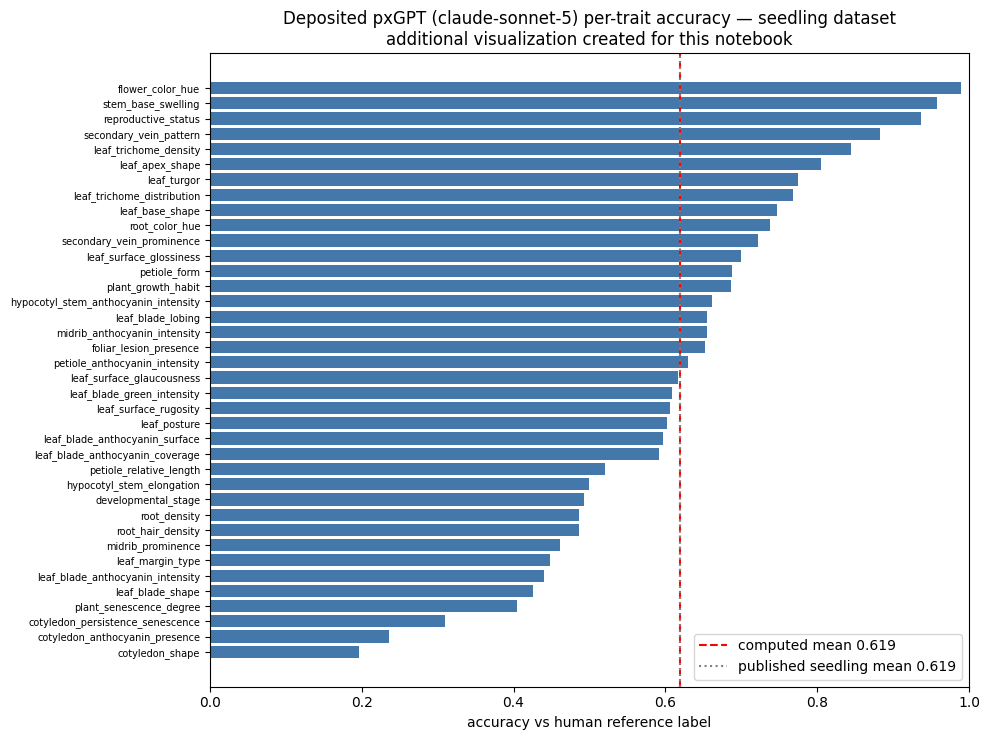

In [ ]:
m = metrics.sort_values("accuracy")
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(np.arange(len(m)), m.accuracy, color="#4477aa")
ax.set_yticks(np.arange(len(m)))
ax.set_yticklabels(m.trait, fontsize=7)
ax.axvline(mean_acc, color="red", ls="--", lw=1.5, label=f"computed mean {mean_acc:.3f}")
ax.axvline(0.619, color="gray", ls=":", lw=1.5, label="published seedling mean 0.619")
ax.set_xlabel("accuracy vs human reference label")
ax.set_xlim(0, 1)
ax.set_title("Deposited pxGPT (claude-sonnet-5) per-trait accuracy — seedling dataset\n"
             "additional visualization created for this notebook")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("seedling_trait_accuracy.png", dpi=110)
plt.show()

## 14. Export the per-trait metrics table

A small CSV export of the per-trait table computed above (kept inside the Colab VM for download via the file browser).

**CSV エクスポート（日本語）:** 上で計算した trait 別指標表を CSV に保存します（Colab のファイルブラウザからダウンロードできます）。

In [ ]:
metrics.to_csv("seedling_pxgpt_trait_metrics.csv", index=False)
print("saved seedling_pxgpt_trait_metrics.csv")
with pd.option_context("display.max_columns", 20, "display.width", 200):
    print(metrics.round(3).head(12).to_string(index=False))

saved seedling_pxgpt_trait_metrics.csv
                               trait   n  accuracy  balanced_accuracy  macro_f1  cohen_kappa
      cotyledon_anthocyanin_presence 225     0.236              0.556     0.247        0.094
    cotyledon_persistence_senescence 284     0.310              0.350     0.218        0.122
                     cotyledon_shape 214     0.196              0.275     0.150        0.035
                 developmental_stage 284     0.493              0.588     0.434        0.107
                    flower_color_hue 282     0.989              0.995     0.554        0.397
              foliar_lesion_presence 224     0.652              0.772     0.522        0.137
hypocotyl_stem_anthocyanin_intensity 284     0.662              0.616     0.628        0.509
           hypocotyl_stem_elongation 284     0.500              0.480     0.406        0.239
                     leaf_apex_shape 215     0.805              0.493     0.532        0.484
                     leaf_base_

## 15. Optional: live Step-3 extraction with your own Anthropic API key

This cell is **skipped automatically** unless you provide a key — it is not needed for anything above. If you want to see the actual Step-3 extraction happen, add your own `ANTHROPIC_API_KEY` (e.g. via Colab's 🔑 Secrets manager with notebook access enabled, or `os.environ` in a scratch cell). It then follows the authors' README single-sample path: build Stage-3 shards from the deposited seedling master schema, fetch the authors' pinned seedling system prompt (which carries the 2.5 cm seedling scale reference), and run `pxgpt schema` on the 7 photos of `s0001`. Expect one LLM call per shard (~2–4 shards); your key is sent only to the Anthropic API and is never printed or saved.

**オプション（日本語）:** 自分の `ANTHROPIC_API_KEY`（Colab のシークレット機能など）を設定した場合のみ、著者の README の手順に従って `s0001` の 7 枚の写真に対する実際の Step 3 抽出を実行します。キーがなければこのセルは自動的にスキップされます。キーは表示・保存されず、Anthropic API にのみ送られます。

In [ ]:
import os
import subprocess

api_key = os.environ.get("ANTHROPIC_API_KEY", "")
if not api_key:
    print("ANTHROPIC_API_KEY is not set -> skipping live extraction (everything above is unaffected).")
    print("To try it: add your key via Colab Secrets with notebook access, then re-run this cell.")
else:
    commit = "9cd5d2e20c810ac73fe48a16e2728f43b2d0dfa6"
    prompt_url = ("https://raw.githubusercontent.com/YaoChengLab/pxgpt/" + commit
                  + "/prompts/phenotype_schema_system_seedling.txt")
    sys_prompt = Path("/content/work/phenotype_schema_system_seedling.txt")
    sys_prompt.write_text(requests.get(prompt_url, timeout=60).text)
    shards = Path("/content/work/shards")
    subprocess.run(["pxgpt", "shard-schema", "--master", str(master),
                    "--shard-dir", str(shards)], check=True, timeout=300)
    env = dict(os.environ, ANTHROPIC_API_KEY=api_key, DEFAULT_PROVIDER="anthropic",
               ANTHROPIC_MODEL="claude-sonnet-5")
    live_json = Path("/content/work/live_s0001.json")
    subprocess.run(["pxgpt", "schema", "--input-folder",
                    str(RELEASE / "datasets/seedling/images/s0001"),
                    "--output", str(live_json), "--shard-dir", str(shards),
                    "--system-prompt", str(sys_prompt)],
                   check=True, env=env, timeout=1800)
    live = json.load(open(live_json))
    for path, val in find_trait(live, "leaf_posture"):
        print("LIVE extraction leaf_posture:", val.get("value"),
              "| deposited claude-sonnet-5 value: 2 | human reference: 2")

ANTHROPIC_API_KEY is not set -> skipping live extraction (everything above is unaffected).
To try it: add your key via Colab Secrets with notebook access, then re-run this cell.


## 16. Interpretation and comparison with the paper

**What was executed:** a fresh Google Colab **CPU** runtime ran this notebook top-to-bottom. All inputs are the authors' own deposited bytes (Zenodo v2.0.0, MD5-verified inside this notebook), and the CLI step uses the authors' pinned v0.4.0 code. Compare the printed values above with the paper's published seedling numbers: mean accuracy **0.619** (38 primary qualitative traits, 9 946 resolved combinations), pxGPT–human raw agreement **0.572**, human–human agreement **0.620**, gap **−0.048** (bootstrap CI below zero).

**Differences and limitations to keep in mind:**
- This is a **partial demonstration**: one dataset (seedling), evaluation stage only. The deposited Step-3 outputs were produced by the authors with claude-sonnet-5; this notebook scores them but does not regenerate them (that requires a paid API key — see the optional cell).
- The scoring population was reconstructed from the deposit itself: qualitative (`nominal` + `ordinal`) traits whose reference status is not `tie_unresolved`. This reproduces the paper's stated 38 traits and 9 946 resolved combinations; remaining deviations from published values would come from unstated details (e.g. how the 93 empty model values across all datasets were treated).
- Agreement-gap CIs from 2000 bootstrap resamples depend on the resampling scheme; our whole-sample resampling with seed 0 is reproducible but not bit-identical to the authors' unreported implementation.
- Matching the published dataset-level number is a plausibility check of the evaluation protocol, not an independent verification of the paper's claims about extraction quality.

**解釈（日本語）:** このノートブックは seedling データセットの評価ステージを、著者自身が公開した Step 3 出力・ヒューマンスコア・参照ラベルで再現しました。計算値は上の出力に表示されており、公表値（平均 accuracy 0.619＝38 trait・9 946 組み合わせ、raw agreement 0.572 / 0.620、gap −0.048）と比較できます。採点対象は `tie_unresolved` を除く qualitative trait で、論文の記載と一致する母集団です。単一データセットの一致は評価プロトコルの妥当性確認であり、論文の主張全体の検証ではありません。

## 17. References and provenance

- Paper: Zheng P.-X., Ou J.-Y., Wu Y.-L., Wang R.-S., Wu T.-L., Hsu T.-C., Lin Y.-C. (2026). *pxGPT: a schema-constrained multimodal large language model framework for plant phenotyping.* Bioinformatics 42(10):btag781. https://doi.org/10.1093/bioinformatics/btag781 (PMCID PMC13719227; evaluation protocol quoted from its Results section, retrieved via Europe PMC fullTextXML).
- Code: https://github.com/YaoChengLab/pxgpt — commit `9cd5d2e20c810ac73fe48a16e2728f43b2d0dfa6` (v0.4.0, 2026-09-24), MIT License. Archival copy: Zenodo https://doi.org/10.5281/zenodo.22931745.
- Data: *Multi-stage Phenotype Dataset of Brassica Cultivars with LLM-assisted Annotations*, Zenodo https://doi.org/10.5281/zenodo.22907554 (v2.0.0), CC BY 4.0. Files used: `pxgpt_release_docs_and_human_annotations.tar.gz`, `pxgpt_release_seedling_dataset.tar.gz` (members: `datasets/seedling/images/s0001/`, `step1_narratives/by_record/s0001.txt`, `step3_json/{claude-sonnet-5,gemma4}/s0001.json`, `schema/`, `model_tables/standardized/seedling_step3_values_long.csv`), `tables/{records,human_scores,reference_labels,trait_dictionary}.csv`. Checksums verified at download time against the Zenodo API-provided MD5 values.
- Prior research guidance (not primary proof): PhenoPaper investigation `p-2942bb14ff5d63920dbe1131380b116a-20261127T105415Z-495984` and its study flow.

**ライセンス:** コードは MIT、データは CC BY 4.0。ノートブック内の図・表は上記デポジットの実データから Colab 上で生成しました。